In [5]:
import pandas as pd
df = pd.read_csv('birthsmokers.txt', sep='\s+')
print(df)

     Wgt  Gest Smoke
0   2940    38   yes
1   3130    38    no
2   2420    36   yes
3   2450    34    no
4   2760    39   yes
5   2440    35   yes
6   3226    40    no
7   3301    42   yes
8   2729    37    no
9   3410    40    no
10  2715    36   yes
11  3095    39    no
12  3130    39   yes
13  3244    39    no
14  2520    35    no
15  2928    39   yes
16  3523    41    no
17  3446    42   yes
18  2920    38    no
19  2957    39   yes
20  3530    42    no
21  2580    38   yes
22  3040    37    no
23  3500    42   yes
24  3200    41   yes
25  3322    39    no
26  3459    40    no
27  3346    42   yes
28  2619    35    no
29  3175    41   yes
30  2740    38   yes
31  2841    36    no


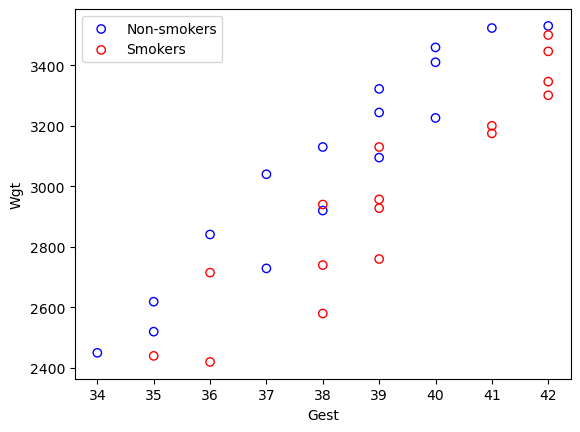

In [6]:
import matplotlib.pyplot as plt

smokers = df[df['Smoke'] == 'yes']
nonsmokers = df[df['Smoke'] == 'no']

plt.scatter(nonsmokers['Gest'], nonsmokers['Wgt'], facecolors='none', edgecolors='blue', label='Non-smokers')
plt.scatter(smokers['Gest'], smokers['Wgt'], facecolors='none', edgecolors='red', label='Smokers')

plt.xlabel('Gest')
plt.ylabel('Wgt')
plt.legend()
plt.show()

In [7]:
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf

model = smf.ols('Wgt ~ Gest + Smoke', data=df).fit()
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:                    Wgt   R-squared:                       0.896
Model:                            OLS   Adj. R-squared:                  0.889
Method:                 Least Squares   F-statistic:                     125.4
Date:                Mon, 12 Oct 2026   Prob (F-statistic):           5.29e-15
Time:                        18:57:28   Log-Likelihood:                -195.82
No. Observations:                  32   AIC:                             397.6
Df Residuals:                      29   BIC:                             402.0
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                   coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------
Intercept    -2389.5729    349.206     -6.843   

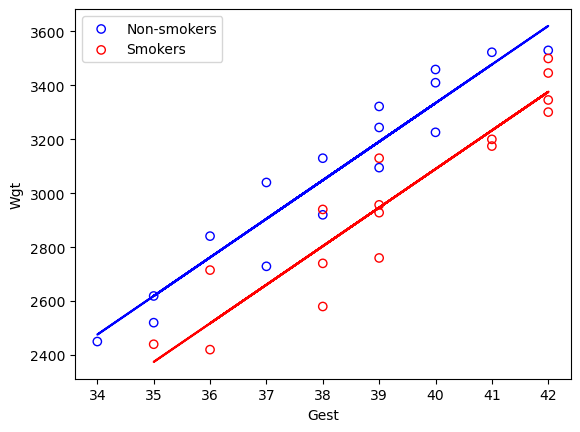

In [8]:
smokers = df[df['Smoke'] == 'yes']
nonsmokers = df[df['Smoke'] == 'no']

plt.scatter(nonsmokers['Gest'], nonsmokers['Wgt'], facecolors='none', edgecolors='blue', label='Non-smokers')
plt.scatter(smokers['Gest'], smokers['Wgt'], facecolors='none', edgecolors='red', label='Smokers')

plt.plot(nonsmokers['Gest'], model.predict(nonsmokers), color='blue')
plt.plot(smokers['Gest'], model.predict(smokers), color='red')

plt.xlabel('Gest')
plt.ylabel('Wgt')
plt.legend()
plt.show()

In [19]:
# betahat = (X^T X)^{-1}X^T Y
import numpy as np
import statsmodels.formula.api as smf

# Design matrix: intercept, Smoke (1 = yes, 0 = no), Gest
X = np.column_stack([np.ones(len(df)),
                     (df['Smoke'] == 'yes').astype(int), #It is similar to Python’s int(), float() and str() functions, 
                                                        #which convert one value at a time, but astype converts a whole column at once.
                     df['Gest']])
y = df['Wgt'].to_numpy()

# beta_hat = (X'X)^{-1} X'y
beta_hat = np.linalg.inv(X.T @ X) @ X.T @ y 
print(beta_hat)

# compare with statsmodels
model = smf.ols('Wgt ~ Gest + Smoke', data=df).fit()
print(model.params.values)

[-2389.5729126   -244.54404019   143.10027312]
[-2389.5729126   -244.54404019   143.10027312]


In [22]:
# Interaction Model
model = smf.ols('Wgt ~ Gest * Smoke', data=df).fit()
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:                    Wgt   R-squared:                       0.897
Model:                            OLS   Adj. R-squared:                  0.886
Method:                 Least Squares   F-statistic:                     81.37
Date:                Mon, 12 Oct 2026   Prob (F-statistic):           6.14e-14
Time:                        20:56:04   Log-Likelihood:                -195.70
No. Observations:                  32   AIC:                             399.4
Df Residuals:                      28   BIC:                             405.3
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                        coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------
Intercept         -2546.1379    501.06

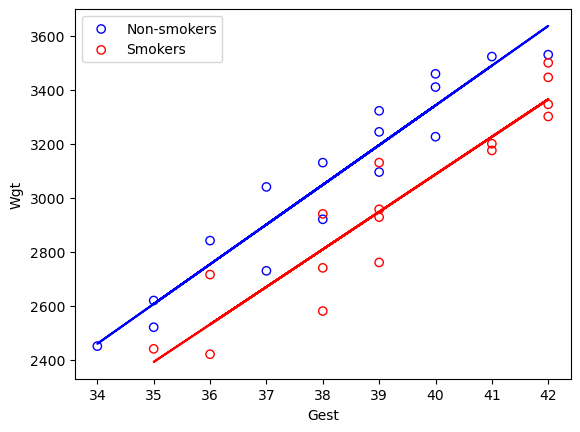

In [24]:
smokers = df[df['Smoke'] == 'yes']
nonsmokers = df[df['Smoke'] == 'no']

plt.scatter(nonsmokers['Gest'], nonsmokers['Wgt'], facecolors='none', edgecolors='blue', label='Non-smokers')
plt.scatter(smokers['Gest'], smokers['Wgt'], facecolors='none', edgecolors='red', label='Smokers')

plt.plot(nonsmokers['Gest'], model.predict(nonsmokers), color='blue')
plt.plot(smokers['Gest'], model.predict(smokers), color='red')

plt.xlabel('Gest')
plt.ylabel('Wgt')
plt.legend()
plt.show()

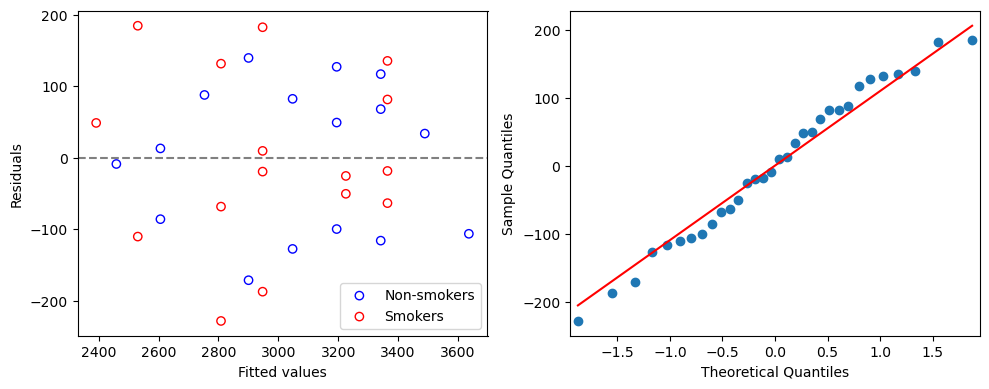

In [27]:
import statsmodels.api as sm

model = smf.ols('Wgt ~ Gest * Smoke', data=df).fit()

fitted = model.fittedvalues
resid = model.resid
is_smoker = df['Smoke'] == 'yes'

fig, ax = plt.subplots(1, 2, figsize=(10, 4))

# Residuals vs fitted
ax[0].scatter(fitted[~is_smoker], resid[~is_smoker], facecolors='none', edgecolors='blue', label='Non-smokers')
ax[0].scatter(fitted[is_smoker], resid[is_smoker], facecolors='none', edgecolors='red', label='Smokers')
ax[0].axhline(0, color='gray', linestyle='--')
ax[0].set_xlabel('Fitted values')
ax[0].set_ylabel('Residuals')
ax[0].legend()

# Normal Q-Q plot
sm.qqplot(resid, line='s', ax=ax[1])

plt.tight_layout()
plt.show()